# Workshop 4 - Governance figures (Seaborn)

Static versions of the governance dashboard charts (`dashboard/governance_app.py`, http://localhost:8050) for the report. Like the dashboard, this notebook reads **only** the newest `datalake_gold/governance_*.parquet` with pandas and uses the same colourblind-friendly Okabe-Ito palette (`dashboard/common/theme.py`), so the report and the dashboard show the same numbers in the same colours.

| Figure | File | Dashboard component | Gold section |
|---|---|---|---|
| 1 | `gov_kpi_summary.png` | KPI cards + quality summary table | `kpi_summary` |
| 2 | `gov_null_rate.png` | Null rate per field | `null_rate` |
| 3 | `gov_outlier_rate.png` | Outlier rate per numeric field | `outlier_rate` |
| 4 | `gov_volume_weekly.png` | Records per week and source | `volume_weekly` |
| 5 | `gov_duplicates.png` | (report only) duplicates before and after dedup | `duplicate_rate` |
| 6 | `gov_quarantine.png` | (report only) quarantine per source and category | `quarantine_rate` |
| 7 | `gov_data_health.png` | Data health per source (US4) | `data_health`, `freshness` |
| 8 | `gov_text_length.png` | (report only) notice length per observatory | `text_length` |

Run it from the repository root or from `notebooks/` after a `gold_processing` run. Figures are written to `workshop_4/figures/`.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "datalake_gold").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from dashboard.common.gold import load_gold
from dashboard.common.theme import CATEGORICAL

FIG = ROOT / "workshop_4" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
PASS, WARN, GREY = "#009E73", "#D55E00", "#999999"      # same status colours as the dashboard badges

snapshot = load_gold("governance", ROOT / "datalake_gold")
assert snapshot.path is not None, "no governance Gold file: run the gold_processing DAG first"
gold = snapshot.frame
SOURCE_NOTE = f"Source: {snapshot.path.name} (Gold layer, generated {snapshot.generated_utc:%Y-%m-%d %H:%M} UTC)"

sns.set_theme(style="whitegrid", palette=CATEGORICAL, font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 12})


def finish(fig, name):
    fig.text(0.01, 0.005, SOURCE_NOTE, fontsize=8, color="#666666", ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG / f"gov_{name}.png", bbox_inches="tight")


print(snapshot.path.name, f"{len(gold):,} rows")
gold.groupby("section").size().rename("rows").to_frame()

governance_20261128_024254.parquet 4,267 rows


,rows
section,
data_health,23
duplicate_rate,21
freshness,7
ingestion_frequency,54
kpi_summary,25
null_rate,124
outlier_rate,4
quarantine_rate,13
schema_compliance,14


## 1. KPI summary against thresholds

One small panel per KPI, because the headline values have different scales (records, percentages from 0.05 % to 100 %). Each panel shows the value as a bar coloured by status (green pass, vermillion warning) and the threshold as a dashed line; a pass / warning label is written next to the bar so the status does not rely on colour alone.

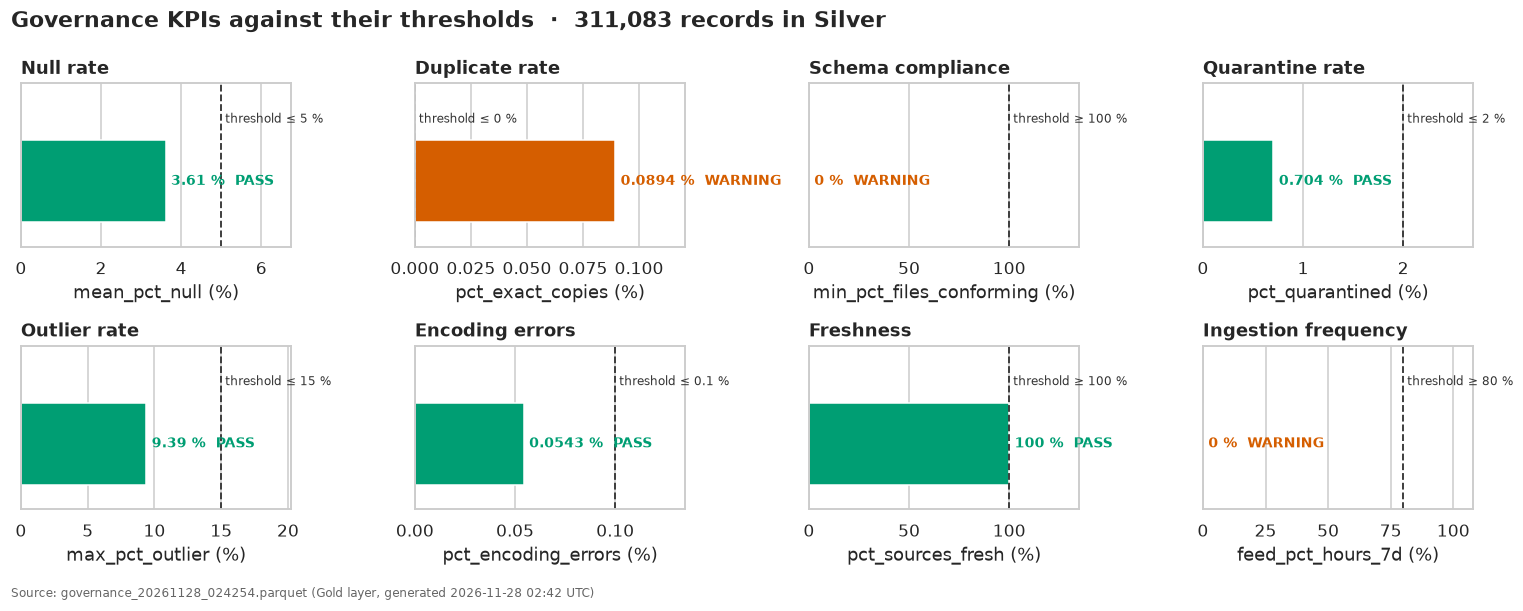

In [2]:
rows = gold[gold.section == "kpi_summary"]
values = rows[~rows.metric.str.startswith("threshold_") & (rows.metric != "status")].set_index("dimension")
limits = rows[rows.metric.str.startswith("threshold_")].set_index("dimension")
status = rows[rows.metric == "status"].set_index("dimension")["value"]
LABELS = {"null_rate": "Null rate", "duplicate_rate": "Duplicate rate", "schema_compliance": "Schema compliance",
          "quarantine_rate": "Quarantine rate", "outlier_rate": "Outlier rate", "text_length": "Encoding errors",
          "freshness": "Freshness", "ingestion_frequency": "Ingestion frequency"}
kpis = [k for k in LABELS if k in values.index]

fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, kpi in zip(axes.flat, kpis):
    value, ok = values.at[kpi, "value"], status.get(kpi)
    colour = GREY if pd.isna(ok) else (PASS if ok >= 1 else WARN)
    ax.barh([0], [value], color=colour, height=0.5)
    if kpi in limits.index:
        limit, rule = limits.at[kpi, "value"], limits.at[kpi, "metric"].removeprefix("threshold_")
        ax.axvline(limit, color="#333333", ls="--", lw=1.2)
        ax.text(limit, 0.34, f" threshold {'≤' if rule == 'max' else '≥'} {limit:g} %", fontsize=8,
                va="bottom", color="#333333")
    top = max(value, limits.at[kpi, "value"] if kpi in limits.index else 0) * 1.35 or 1
    ax.set_xlim(0, top)
    ax.set_ylim(-0.4, 0.6)      # room above the bar for the threshold label
    ax.text(value + top * 0.02, 0, f"{value:.3g} %  {'PASS' if ok >= 1 else 'WARNING'}", va="center",
            fontsize=9, color=colour, fontweight="bold")
    ax.set_yticks([]); ax.set_title(LABELS[kpi], loc="left"); ax.set_xlabel(values.at[kpi, "metric"] + " (%)")
for ax in axes.flat[len(kpis):]:
    ax.axis("off")
fig.suptitle(f"Governance KPIs against their thresholds  ·  {values.at['volume', 'value']:,.0f} records in Silver",
             x=0.01, ha="left", fontweight="bold")
finish(fig, "kpi_summary")

## 2. Null rate per field

Horizontal bars, sorted by severity, because the field names are long and a ranking is the question ("which fields are the emptiest?"). Colour encodes the Silver topic, so the reader sees that most gaps belong to two small topics (`volcano_updates`, `eruptions`) and are structural (findings F01-F04), not ingestion failures.

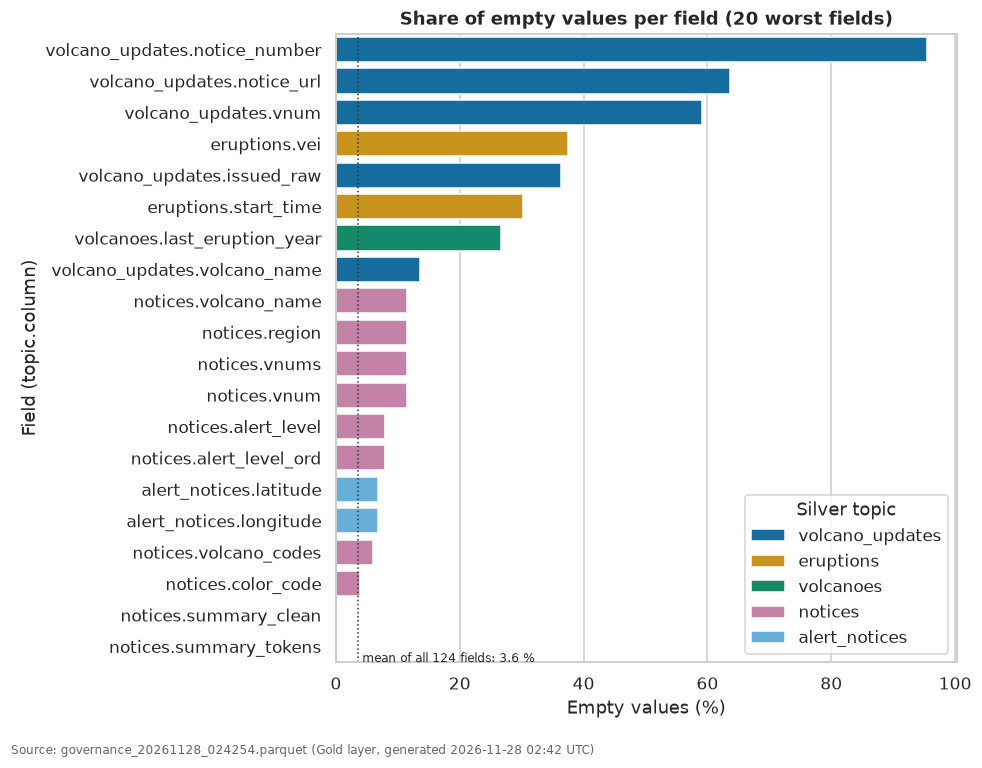

In [3]:
nulls = gold[(gold.section == "null_rate") & (gold.value > 0)].nlargest(20, "value").copy()
nulls["topic"] = nulls.dimension.str.split(".").str[0]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=nulls, y="dimension", x="value", hue="topic", dodge=False, ax=ax)
ax.set(title="Share of empty values per field (20 worst fields)", xlabel="Empty values (%)", ylabel="Field (topic.column)")
ax.legend(title="Silver topic", loc="lower right")
mean = gold[(gold.section == "null_rate")].value.mean()
ax.axvline(mean, color="#333333", ls=":", lw=1)
ax.text(mean, len(nulls) - 0.5, f" mean of all {len(gold[gold.section == 'null_rate'])} fields: {mean:.1f} %", fontsize=8)
finish(fig, "null_rate")

## 3. Outlier rate per numeric field

Grouped bars compare the KPI (IQR fences per volcano over all records) with the flags Silver writes per Bronze file (finding F19). The gap between the two bars is the point of the chart: per-file fences under-count depth outliers because a file of one volcano judges it only against itself.

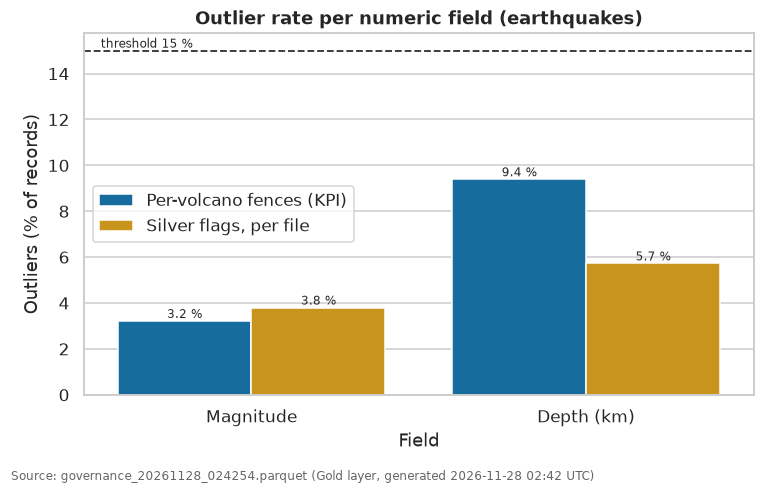

In [4]:
out = gold[gold.section == "outlier_rate"].copy()
out["criterion"] = out.metric.map({"pct_outlier": "Per-volcano fences (KPI)", "pct_outlier_silver_flags": "Silver flags, per file"})
out["field"] = out.dimension.map({"earthquakes.mag": "Magnitude", "earthquakes.depth_km": "Depth (km)"})
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=out, x="field", y="value", hue="criterion", ax=ax)
limit = limits.at["outlier_rate", "value"] if "outlier_rate" in limits.index else None
if limit is not None:
    ax.axhline(limit, color="#333333", ls="--", lw=1.2)
    ax.text(-0.45, limit, f"threshold {limit:g} %", va="bottom", fontsize=8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f %%", fontsize=8)
ax.set(title="Outlier rate per numeric field (earthquakes)", xlabel="Field", ylabel="Outliers (% of records)")
ax.legend(title=None)
finish(fig, "outlier_rate")

## 4. Records per week and source

A line per source, because it is a time series of 16 years. The y axis is logarithmic: earthquakes (~100-1,000 per week) and HANS notices (~10-30 per week) differ by two orders of magnitude and would otherwise flatten each other. Peaks such as Kilauea 2018 stand out.

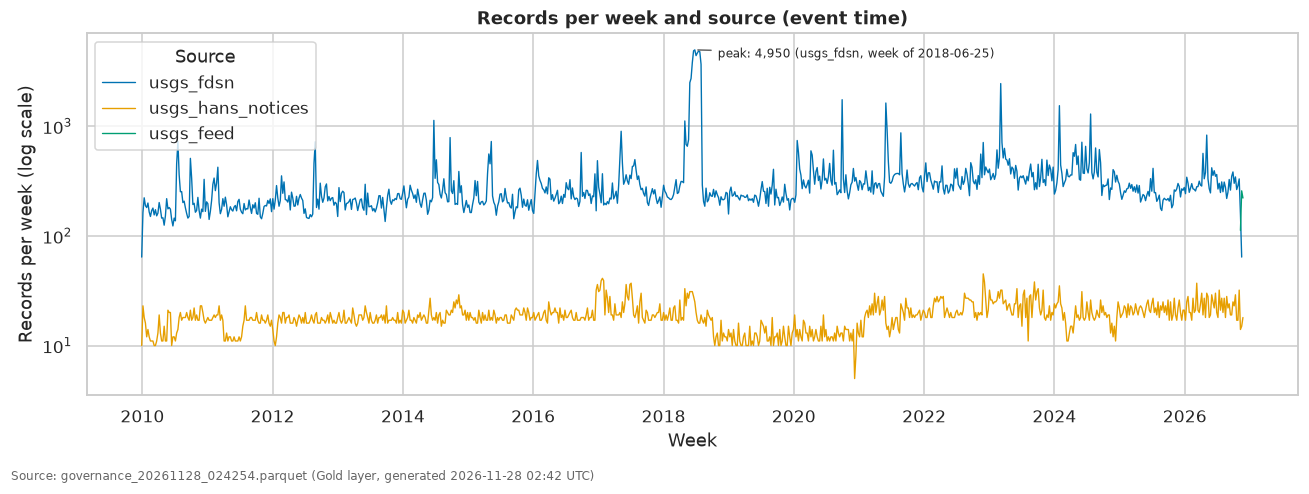

In [5]:
vol = gold[(gold.section == "volume_weekly") & (gold.metric == "records_by_source")].copy()
if vol.empty:      # Gold written before Workshop 4: per topic only
    vol = gold[(gold.section == "volume_weekly") & (gold.metric == "records")].copy()
vol["week"] = pd.to_datetime(vol.period)
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.lineplot(data=vol.sort_values("week"), x="week", y="value", hue="dimension", lw=0.9, ax=ax)
ax.set_yscale("log")
ax.set(title="Records per week and source (event time)", xlabel="Week", ylabel="Records per week (log scale)")
ax.legend(title="Source")
peak = vol.loc[vol.value.idxmax()]
ax.annotate(f"peak: {peak.value:,.0f} ({peak.dimension}, week of {peak.week:%Y-%m-%d})", (peak.week, peak.value),
            xytext=(15, -5), textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-", "color": "#666666"})
finish(fig, "volume_weekly")

## 5. Duplicates before and after deduplication

Bars on a log axis, because the four quantities span three orders of magnitude (19.8 % of FDSN records repeated before dedup, < 0.1 % exact copies after it). Exact and same-value copies are errors; real revisions are legitimate versions (findings F06-F09).

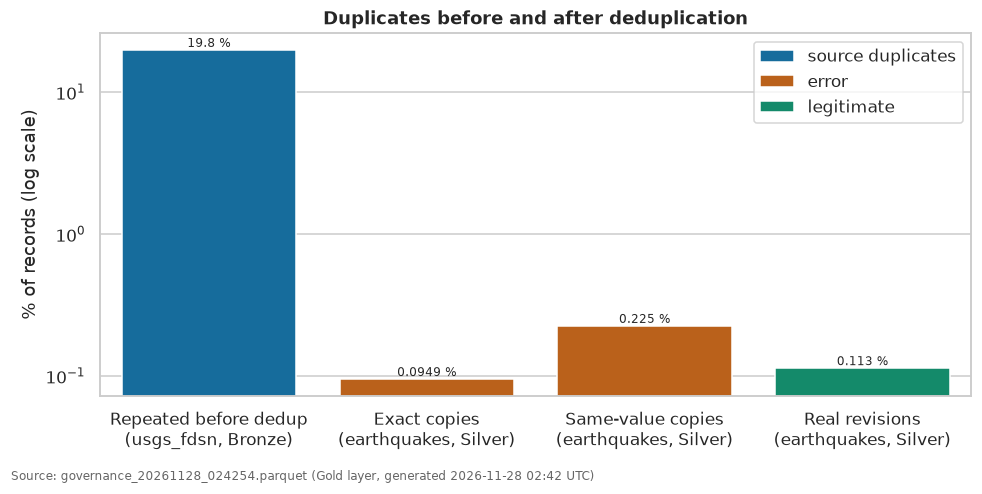

In [6]:
dup = gold[gold.section == "duplicate_rate"]
eq = dup[dup.dimension == "earthquakes"].set_index("metric")["value"]
before = dup[(dup.dimension == "usgs_fdsn") & (dup.metric == "pct_repeated_before_dedup")]["value"]
bars = pd.DataFrame({
    "measure": ["Repeated before dedup\n(usgs_fdsn, Bronze)", "Exact copies\n(earthquakes, Silver)",
                "Same-value copies\n(earthquakes, Silver)", "Real revisions\n(earthquakes, Silver)"],
    "value": [before.iloc[0] if len(before) else np.nan, eq.get("pct_exact_copies"), eq.get("pct_same_value_copies"),
              eq.get("pct_real_revisions")],
    "kind": ["source duplicates", "error", "error", "legitimate"]})
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=bars, x="measure", y="value", hue="kind",
            palette={"source duplicates": CATEGORICAL[0], "error": WARN, "legitimate": PASS}, dodge=False, ax=ax)
ax.set_yscale("log")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3g %%", fontsize=8)
ax.set(title="Duplicates before and after deduplication", xlabel=None, ylabel="% of records (log scale)")
ax.legend(title=None)
finish(fig, "duplicates")

## 6. Quarantine per source and category

Stacked horizontal bars: one bar per source, split by the category of the rejection reason. Business-rule rejections (out of scope by design) are separated from source defects and pipeline errors, so a large bar is not misread as a problem.

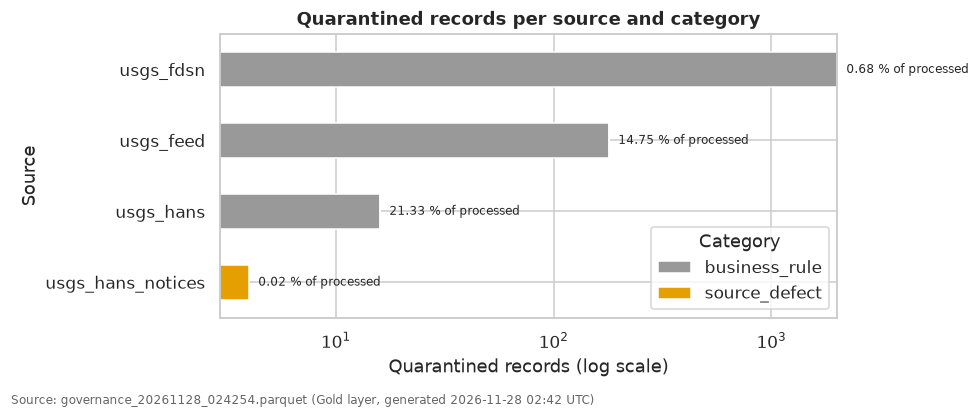

In [7]:
q = gold[(gold.section == "quarantine_rate") & (gold.metric == "records_by_reason")].copy()
q[["source", "reason", "category"]] = q.dimension.str.split("|", expand=True)
pivot = q.pivot_table(index="source", columns="category", values="value", aggfunc="sum", fill_value=0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values().index]
colours = {"business_rule": GREY, "source_defect": CATEGORICAL[1], "pipeline_error": WARN}
fig, ax = plt.subplots(figsize=(9, 3.8))
pivot.plot.barh(stacked=True, ax=ax, color=[colours.get(c, CATEGORICAL[4]) for c in pivot.columns], log=True)
rates = gold[(gold.section == "quarantine_rate") & (gold.metric == "pct_quarantined")].set_index("dimension")["value"]
for i, source in enumerate(pivot.index):
    ax.text(pivot.loc[source].sum() * 1.1, i, f"{rates.get(source, np.nan):.2f} % of processed", va="center", fontsize=8)
ax.set(title="Quarantined records per source and category", xlabel="Quarantined records (log scale)", ylabel="Source")
ax.legend(title="Category", loc="lower right")
finish(fig, "quarantine")

## 7. Data health per source (US4)

A heatmap of ages (hours, log colour scale) answers "how fresh is each source?" at a glance: rows are sources, columns are the age of the newest file and of the watermark. The cell text gives the exact value; GVP has no watermark timestamp (database version), shown as an empty cell.

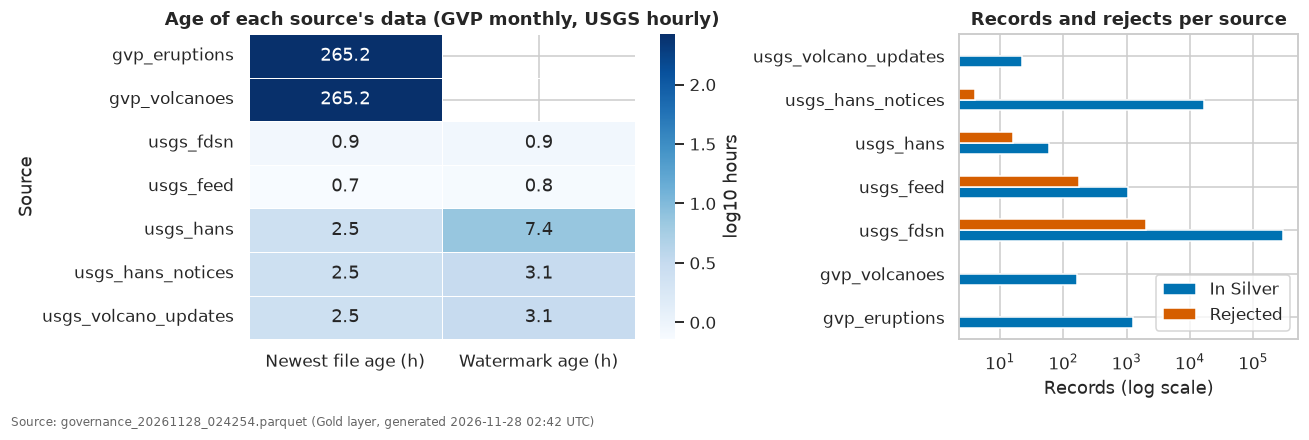

In [8]:
health = pd.concat([gold[gold.section == "data_health"], gold[gold.section == "freshness"]])
wide = health.pivot_table(index="dimension", columns="metric", values="value", aggfunc="first")
ages = wide.reindex(columns=["hours_since_last", "watermark_age_hours"]).rename(
    columns={"hours_since_last": "Newest file age (h)", "watermark_age_hours": "Watermark age (h)"})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1.4]})
# neutral blues, not red: an age is only bad relative to its schedule (GVP is refreshed monthly, the
# USGS sources hourly); the pass / warning judgement is the Freshness KPI of figure 1
sns.heatmap(np.log10(ages.clip(lower=0.1)), annot=ages.round(1), fmt="g", cmap="Blues", cbar_kws={"label": "log10 hours"},
            linewidths=0.5, ax=axes[0])
axes[0].set(title="Age of each source's data (GVP monthly, USGS hourly)", xlabel=None, ylabel="Source")
counts = wide.reindex(columns=["records_in_silver", "rejected_records"]).fillna(0)
counts.plot.barh(ax=axes[1], logx=True, color=[CATEGORICAL[0], WARN])
axes[1].set(title="Records and rejects per source", xlabel="Records (log scale)", ylabel=None)
axes[1].legend(["In Silver", "Rejected"], loc="lower right")
finish(fig, "data_health")

## 8. Notice length per observatory

Median length of the HANS notices per year and observatory (lines, a time series). A sudden drop or jump for one observatory would mean a template change or a broken cleaning step; the encoding-error rate, the sub-metric of the same KPI, is written in the title.

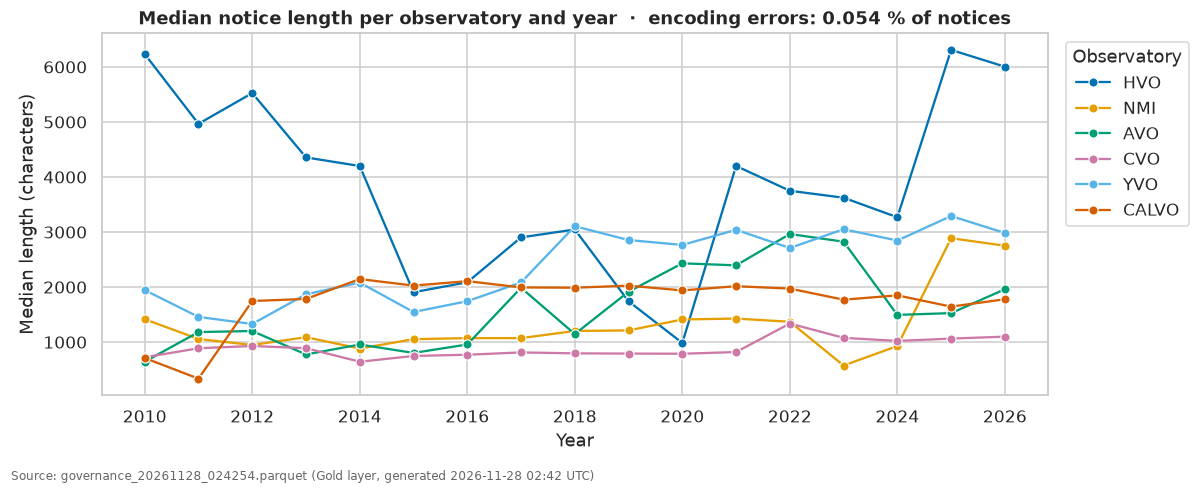

In [9]:
tl = gold[(gold.section == "text_length") & (gold.metric == "median_chars") & gold.period.notna()].copy()
tl["year"] = pd.to_datetime(tl.period).dt.year
tl["dimension"] = tl.dimension.str.upper()
enc = gold[(gold.section == "text_length") & (gold.metric == "pct_encoding_errors")]["value"]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=tl.sort_values("year"), x="year", y="value", hue="dimension", marker="o", ax=ax)
ax.set(title=f"Median notice length per observatory and year  ·  encoding errors: {enc.iloc[0]:.3f} % of notices",
       xlabel="Year", ylabel="Median length (characters)")
ax.legend(title="Observatory", loc="upper left", bbox_to_anchor=(1.01, 1))
finish(fig, "text_length")

## Summary

Every KPI with its headline value, threshold and status: the same rows as the dashboard's quality summary table.

In [10]:
table = values[["metric", "value"]].join(limits[["metric", "value"]].rename(columns={"metric": "rule", "value": "threshold"}))
table["status"] = status.map({1.0: "pass", 0.0: "warning"})
table.round(3)

,metric,value,rule,threshold,status
dimension,,,,,
volume,records_in_silver,311083.000,NaN,NaN,NaN
null_rate,mean_pct_null,3.611,threshold_max,5.0,pass
duplicate_rate,pct_exact_copies,0.089,threshold_max,0.0,warning
schema_compliance,min_pct_files_conforming,0.000,threshold_min,100.0,warning
quarantine_rate,pct_quarantined,0.704,threshold_max,2.0,pass
outlier_rate,max_pct_outlier,9.394,threshold_max,15.0,pass
text_length,pct_encoding_errors,0.054,threshold_max,0.1,pass
freshness,pct_sources_fresh,100.000,threshold_min,100.0,pass
ingestion_frequency,feed_pct_hours_7d,0.000,threshold_min,80.0,warning
